In [14]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict


In [15]:
class EmailState (TypedDict):

    receipnts_email=list[str]
    topic : str
    email : str

    subject : str
    body : str

    feedback : str
    approval : bool
    attempts : int
    

In [16]:
def generate_email(state:EmailState):
    pass

def Human_Review(state:EmailState):
    pass


def Regenerate(state:EmailState):
    pass


def Gmail_calling(state:EmailState):
    pass

def attach_resume(state:EmailState):
    pass


In [17]:
# # Human Review Function

# from langgraph.types import interrupt

# def Human_Review(state: EmailState):
#     decision = interrupt({
#         "subject": state["subject"],
#         "email_body": state["email_body"],
#         "message": "Approve or reject this email."
#     })

#     return {
#         "approved": decision["approved"],
#         "feedback": decision.get("feedback", "")
#     }


# # Routing Function - Function that are used for the Check Condition , its not part of any node in the graph

# def check_decision(state: EmailState):
#     if state["approved"]:
#         return "approved"
#     else:
#         return "rejected"

In [20]:

graph = StateGraph(EmailState)

# Add nodes
graph.add_node("generate_email", generate_email)
graph.add_node("Human_Review", Human_Review)
graph.add_node("Regenerate", Regenerate)
graph.add_node("Gmail_calling", Gmail_calling)
graph.add_node("Attach_resume", attach_resume)

# Normal edges
graph.add_edge(START, "generate_email")
graph.add_edge("generate_email", "Human_Review")

# Conditional routing
graph.add_conditional_edges(
    "Human_Review",
    check_decision,
    {
        "approved": "Gmail_calling",
        "rejected": "Regenerate"
    }
)

# Rejection loop
graph.add_edge("Regenerate", "Human_Review")

# Approved path
graph.add_edge("Gmail_calling", "Attach_resume")
graph.add_edge("Attach_resume", END)

workflow = graph.compile()


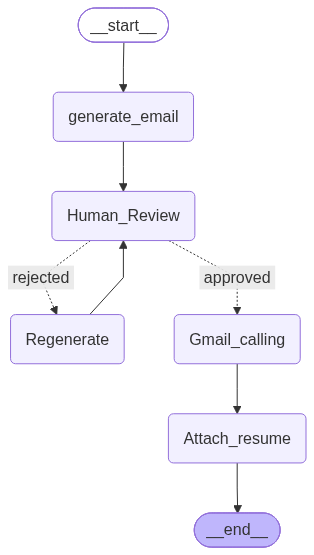

In [22]:
workflow